# Task 3 - Matplotlib (4 charts) - Adidas Sales Dataset

In [1]:
import pandas as pd

# Show all columns in the printed output
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)

# Upload the file to Colab first (left sidebar > Files > Upload), then set the exact name (.xlsx or .csv):
file = "Adidas_US_Sales_Datasets.xlsx"

raw = pd.read_csv(file, header=None) if file.endswith(".csv") else pd.read_excel(file, header=None)

# Find the header row automatically (the row that contains "Retailer")
mask = raw.apply(lambda r: r.astype(str).str.contains("Retailer", case=False).any(), axis=1)
header_row = mask.idxmax()

df = raw.iloc[header_row + 1:].copy()
df.columns = raw.iloc[header_row].astype(str).str.strip()
df.columns.name = None
df = df.dropna(how="all").dropna(axis=1, how="all").reset_index(drop=True)

# Convert numeric columns (removes $ , % if present)
for col in ["Price per Unit", "Units Sold", "Total Sales", "Operating Profit", "Operating Margin"]:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(r"[$,%]", "", regex=True), errors="coerce")

df["Invoice Date"] = pd.to_datetime(df["Invoice Date"], errors="coerce")

df = df.drop_duplicates()

import matplotlib.pyplot as plt

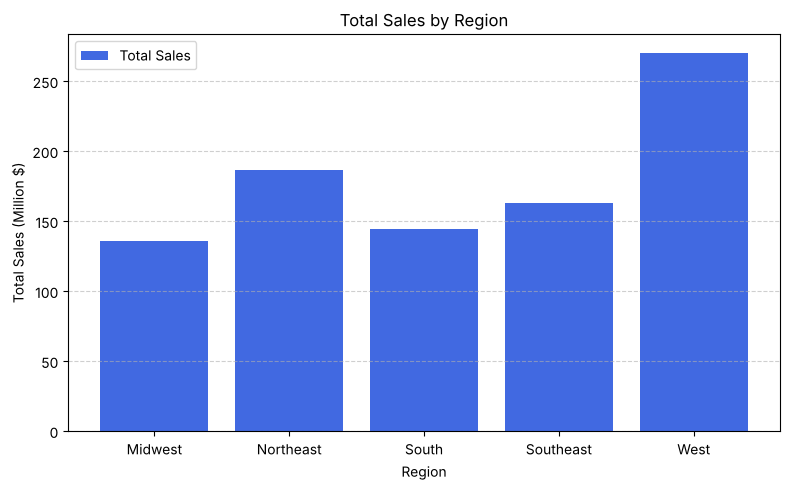

In [2]:
# Chart 1: Bar chart - total sales by region
sales = df.groupby("Region")["Total Sales"].sum() / 1e6
plt.figure(figsize=(8, 5))
plt.bar(sales.index, sales.values, color="royalblue", label="Total Sales")
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales (Million $)")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

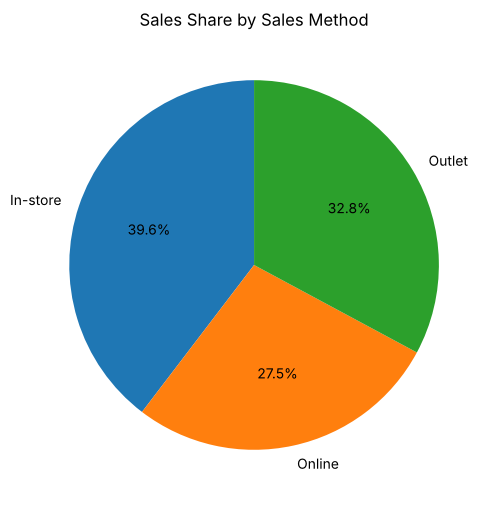

In [3]:
# Chart 2: Pie chart - share of sales by sales method
method = df.groupby("Sales Method")["Total Sales"].sum()
plt.figure(figsize=(6, 6))
plt.pie(method.values, labels=method.index, autopct="%1.1f%%", startangle=90)
plt.title("Sales Share by Sales Method")
plt.show()

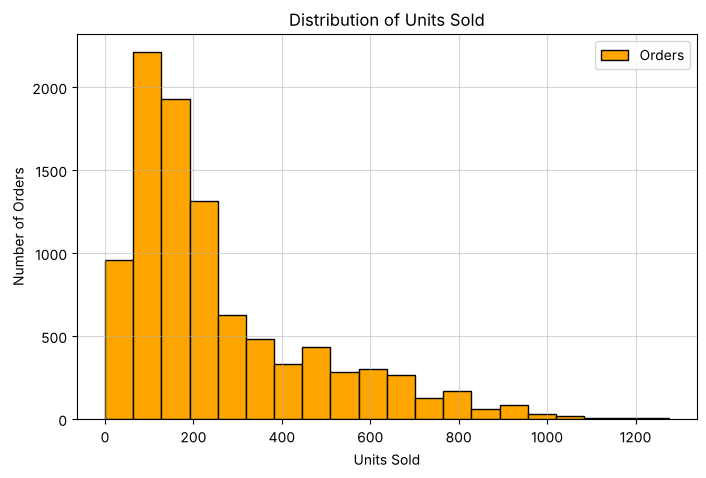

In [4]:
# Chart 3: Histogram - distribution of units sold
plt.figure(figsize=(8, 5))
plt.hist(df["Units Sold"], bins=20, color="orange", edgecolor="black", label="Orders")
plt.title("Distribution of Units Sold")
plt.xlabel("Units Sold")
plt.ylabel("Number of Orders")
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

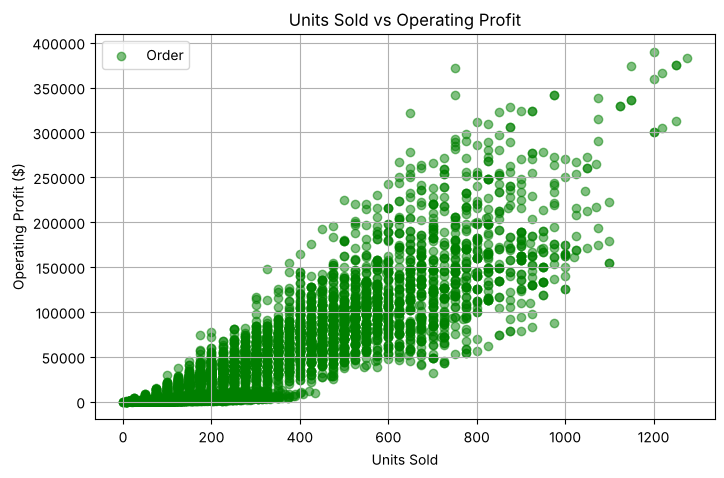

In [5]:
# Chart 4: Scatter plot - units sold vs operating profit
plt.figure(figsize=(8, 5))
plt.scatter(df["Units Sold"], df["Operating Profit"], color="green", alpha=0.5, label="Order")
plt.title("Units Sold vs Operating Profit")
plt.xlabel("Units Sold")
plt.ylabel("Operating Profit ($)")
plt.legend()
plt.grid(True)
plt.show()